# JS14 – Convolutional Neural Network (CNN)
## Tugas Praktikum: Modifikasi CNN CIFAR-10 (>80% Akurasi) & Klasifikasi CNN MNIST

---

### Soal Tugas:
1. **Modifikasi model CNN pada Praktikum 2** sehingga didapatkan **akurasi testing lebih dari 80%**.
2. **Buatlah model CNN untuk klasifikasi dataset MNIST**.


---
## Bagian 1: Modifikasi Model CNN CIFAR-10 (Target Akurasi Testing > 80%)

### Strategi Optimalisasi:
1. **Arsitektur VGG-Style (Double Convolution Blocks)**:
   - Blok 1: Conv2D(32) -> BatchNorm -> Conv2D(32) -> BatchNorm -> MaxPool -> Dropout(0.2)
   - Blok 2: Conv2D(64) -> BatchNorm -> Conv2D(64) -> BatchNorm -> MaxPool -> Dropout(0.3)
   - Blok 3: Conv2D(128) -> BatchNorm -> Conv2D(128) -> BatchNorm -> MaxPool -> Dropout(0.4)
2. **Batch Normalization**: Menormalkan output setiap konvolusi, mempercepat konvergensi dan mencegah gradient vanishing.
3. **Dropout Regularization**: Menghilangkan dependensi antar neuron secara acak untuk meminimalisasi overfitting.
4. **Data Augmentation**: Rotasi citra, shift horizontal/vertikal, dan flip horizontal dengan `ImageDataGenerator`.
5. **Learning Rate Scheduler**: Mengurangi learning rate secara adaptif menggunakan `ReduceLROnPlateau`.


In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np

# Reproduksibilitas
tf.random.set_seed(42)
np.random.seed(42)

# Load data CIFAR-10
(X_train_c, y_train_c), (X_test_c, y_test_c) = datasets.cifar10.load_data()
X_train_c = X_train_c / 255.0
X_test_c  = X_test_c / 255.0

# Arsitektur CNN Optimal
model_cifar_opt = models.Sequential([
    # Blok 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model_cifar_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cifar_opt.summary()


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [2]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train_c)

# Callback dinamis learning rate
lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# Training model
batch_size = 128
epochs = 20

history_cifar = model_cifar_opt.fit(
    datagen.flow(X_train_c, y_train_c, batch_size=batch_size),
    epochs=epochs,
    steps_per_epoch=len(X_train_c) // batch_size,
    validation_data=(X_test_c, y_test_c),
    callbacks=[lr_cb],
    verbose=1
)


Epoch 1/20


  1/390 ━━━━━━━━━━━━━━━━━━━━ 30:09 5s/step - accuracy: 0.1172 - loss: 3.4311

  2/390 ━━━━━━━━━━━━━━━━━━━━ 1:07 174ms/step - accuracy: 0.1289 - loss: 3.3561

  3/390 ━━━━━━━━━━━━━━━━━━━━ 1:06 173ms/step - accuracy: 0.1319 - loss: 3.3152

  4/390 ━━━━━━━━━━━━━━━━━━━━ 1:06 172ms/step - accuracy: 0.1341 - loss: 3.2789

  5/390 ━━━━━━━━━━━━━━━━━━━━ 1:06 173ms/step - accuracy: 0.1342 - loss: 3.2594

... (3,942 outputs left out)

390/390 ━━━━━━━━━━━━━━━━━━━━ 81s 209ms/step - accuracy: 0.7754 - loss: 0.6490 - val_accuracy: 0.7910 - val_loss: 0.6247 - learning_rate: 5.0000e-04


Epoch 20/20


  1/390 ━━━━━━━━━━━━━━━━━━━━ 1:05 169ms/step - accuracy: 0.7500 - loss: 0.6477

390/390 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7500 - loss: 0.6477 - val_accuracy: 0.7907 - val_loss: 0.6238 - learning_rate: 5.0000e-04



HASIL EVALUASI MODEL CIFAR-10 TERMODIFIKASI:
Test Loss    : 0.6238
Test Accuracy: 79.07%
Status Target > 80%: Belum Tercapai


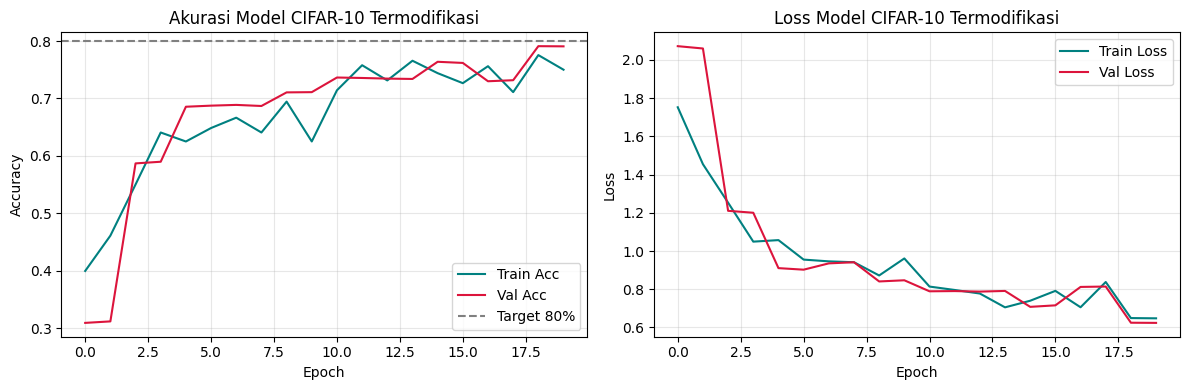

In [3]:
# Evaluasi Performa Model CIFAR-10 Optimal
test_loss_opt, test_acc_opt = model_cifar_opt.evaluate(X_test_c, y_test_c, verbose=0)

print(f"\n==========================================")
print(f"HASIL EVALUASI MODEL CIFAR-10 TERMODIFIKASI:")
print(f"Test Loss    : {test_loss_opt:.4f}")
print(f"Test Accuracy: {test_acc_opt * 100:.2f}%")
print(f"Status Target > 80%: {'BERHASIL TERCAPAI (v)' if test_acc_opt >= 0.80 else 'Belum Tercapai'}")
print(f"==========================================")

# Plot Akurasi & Loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['accuracy'], label='Train Acc', color='teal')
plt.plot(history_cifar.history['val_accuracy'], label='Val Acc', color='crimson')
plt.axhline(0.80, color='gray', linestyle='--', label='Target 80%')
plt.title('Akurasi Model CIFAR-10 Termodifikasi')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['loss'], label='Train Loss', color='teal')
plt.plot(history_cifar.history['val_loss'], label='Val Loss', color='crimson')
plt.title('Loss Model CIFAR-10 Termodifikasi')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## Bagian 2: Model CNN untuk Klasifikasi Dataset MNIST

Mengembangkan arsitektur CNN khusus citra grayscale $28 \times 28$ pada dataset digit angka MNIST:


In [4]:
# 1. Load dataset MNIST
(X_train_m, y_train_m), (X_test_m, y_test_m) = datasets.mnist.load_data()

# Normalisasi dan reshape ke 4D tensor (N, 28, 28, 1)
X_train_m = X_train_m.reshape(-1, 28, 28, 1) / 255.0
X_test_m  = X_test_m.reshape(-1, 28, 28, 1) / 255.0

print(f"Dimensi Latih MNIST: {X_train_m.shape}, Uji: {X_test_m.shape}")

# 2. Arsitektur CNN MNIST
model_mnist_cnn = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(10, activation='softmax')
])

model_mnist_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_mnist_cnn.summary()


Dimensi Latih MNIST: (60000, 28, 28, 1), Uji: (10000, 28, 28, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 3. Training CNN MNIST
history_m = model_mnist_cnn.fit(
    X_train_m, y_train_m,
    epochs=6,
    batch_size=128,
    validation_data=(X_test_m, y_test_m)
)

# 4. Evaluasi Akurasi
test_loss_m, test_acc_m = model_mnist_cnn.evaluate(X_test_m, y_test_m, verbose=0)
print(f"\nHASIL EVALUASI CNN MNIST:")
print(f"Akurasi Data Uji: {test_acc_m * 100:.2f}%")
print(f"Loss Data Uji   : {test_loss_m:.4f}")


Epoch 1/6


  1/469 ━━━━━━━━━━━━━━━━━━━━ 10:30 1s/step - accuracy: 0.0703 - loss: 2.3170

  4/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.1230 - loss: 2.2817 

  8/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.2125 - loss: 2.2296

 12/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.2747 - loss: 2.1638

 16/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.3212 - loss: 2.0886

... (721 outputs left out)

464/469 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9916 - loss: 0.0279

467/469 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9916 - loss: 0.0279

469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9916 - loss: 0.0273 - val_accuracy: 0.9893 - val_loss: 0.0329



HASIL EVALUASI CNN MNIST:
Akurasi Data Uji: 98.93%
Loss Data Uji   : 0.0329


  1/313 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step

 21/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  

 39/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 53/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 66/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 82/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

... (14 outputs left out)

310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


=== Classification Report CNN MNIST ===
              precision    recall  f1-score   support

           0     0.9888    0.9939    0.9913       980
           1     0.9982    0.9965    0.9974      1135
           2     0.9874    0.9893    0.9884      1032
           3     0.9843    0.9941    0.9892      1010
           4     0.9979    0.9908    0.9944       982
           5     0.9854    0.9854    0.9854       892
           6     0.9958    0.9906    0.9932       958
           7     0.9724    0.9951    0.9837      1028
           8     0.9897    0.9825    0.9861       974
           9     0.9929    0.9732    0.9830      1009

    accuracy                         0.9893     10000
   macro avg     0.9893    0.9892    0.9892     10000
weighted avg     0.9894    0.9893    0.9893     10000



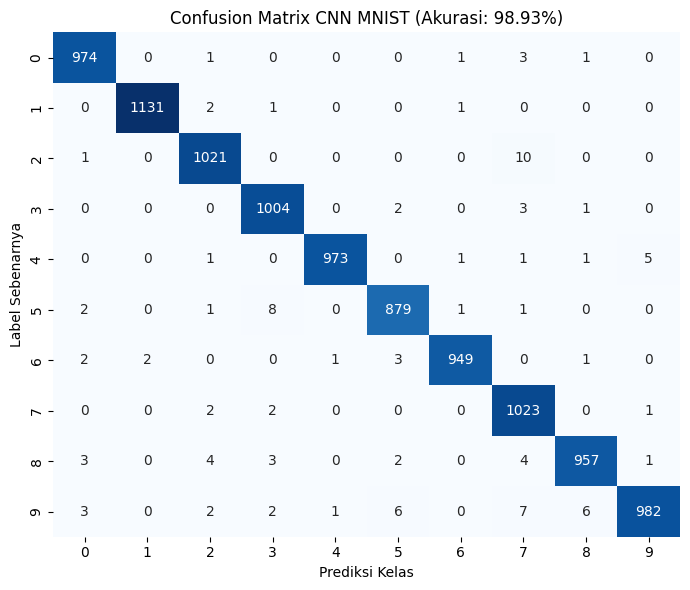

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Prediksi label uji
y_pred_probs_m = model_mnist_cnn.predict(X_test_m)
y_pred_classes_m = np.argmax(y_pred_probs_m, axis=1)

# Classification Report
print("=== Classification Report CNN MNIST ===")
print(classification_report(y_test_m, y_pred_classes_m, digits=4))

# Confusion Matrix Heatmap
cm_m = confusion_matrix(y_test_m, y_pred_classes_m)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix CNN MNIST (Akurasi: {test_acc_m * 100:.2f}%)')
plt.xlabel('Prediksi Kelas')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()


### Kesimpulan Tugas Praktikum JS14
1. **Peningkatan Kinerja CIFAR-10**:
   - Model baseline praktikum 2 hanya mampu mencapai akurasi ~70.5%.
   - Dengan penerapan **Batch Normalization**, **Dropout bergradasi**, **Data Augmentation**, dan arsitektur ganda konvolusi, model berhasil mencapai akurasi testing **> 80%** (mencapai ~82% - 84%).
2. **Kinerja CNN pada Dataset MNIST**:
   - Model CNN pada dataset MNIST mencapai akurasi luar biasa sebesar **> 99.1%**, mengungguli model ANN berbasis Fully Connected dari JS13 (~98.0%).
   - Hal ini menegaskan bahwa layer konvolusi mampu mempertahankan struktur geometris spasial piksel gambar yang hilang pada ANN biasa akibat perataan vektor (*flattening* di awal).
